# Fine-tuning SLM untuk Chatbot Tim Legal (Kriteria 1)

**Proyek Akhir — Pengembangan Generative AI berbasis LLM (Dicoding)** · Romi Fadli

Notebook ini menyiapkan "otak" chatbot: sebuah *Small Language Model* yang di-*fine-tune* dengan
**QLoRA** (Unsloth + TRL `SFTTrainer`) menggunakan dataset instruksi berbahasa Indonesia
[`Ichsan2895/alpaca-gpt4-indonesian`](https://huggingface.co/datasets/Ichsan2895/alpaca-gpt4-indonesian).

| Komponen | Pilihan |
|---|---|
| Base model | `Qwen/Qwen2.5-1.5B` (model *pre-trained* resmi Qwen untuk text generation, didukung Unsloth) |
| Chat template | ChatML (`<\|im_start\|>` / `<\|im_end\|>`) |
| Kuantisasi | 4-bit NF4 + **double quantization** (QLoRA) |
| Adapter LoRA | Multi-Head Attention (`q,k,v,o_proj`) **dan** Feed Forward Network (`gate,up,down_proj`) |
| Training | `SFTTrainer` 800 steps × 2 eksperimen, dengan validation set |
| Output | Model terbaik di-*merge* (16-bit) dan di-*push* ke Hugging Face Hub |

## 1. Instalasi & konfigurasi
Token Hugging Face **tidak ditulis di notebook**. Token dibaca dari *Kaggle Secrets* lalu disimpan
sebagai *environment variable* `HF_TOKEN`.

In [1]:
import subprocess, sys
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "unsloth"], check=True)

CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'unsloth'], returncode=0)

In [2]:
import os, gc, json, math, random
import torch
from kaggle_secrets import UserSecretsClient

os.environ["HF_TOKEN"] = UserSecretsClient().get_secret("HF_TOKEN")
assert os.environ["HF_TOKEN"], "HF_TOKEN belum tersedia"

SEED = 42
random.seed(SEED); torch.manual_seed(SEED)
BASE_MODEL = "Qwen/Qwen2.5-1.5B"
HF_REPO = "tnromy/Qwen2.5-1.5B-Legal-ID-SFT"
MAX_SEQ_LEN = 1024
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


## 2. Dataset: dari format Alpaca mentah ke Chat Template
Dataset berisi kolom `input` (instruksi) dan `output` (jawaban). Kolom indeks `Unnamed: 0` dibuang.

In [3]:
from datasets import load_dataset

raw = load_dataset("Ichsan2895/alpaca-gpt4-indonesian", split="train")
raw = raw.remove_columns([c for c in raw.column_names if c.startswith("Unnamed")])
raw = raw.filter(lambda r: r["input"] and r["output"] and len(r["input"]) + len(r["output"]) < 3000)
print(raw)
print("\nContoh dataset yang BELUM di-mapping:")
print(json.dumps(raw[0], ensure_ascii=False, indent=2))

README.md:   0%|          | 0.00/1.91k [00:00<?, ?B/s]

alpaca-gpt4-indonesia.csv: reconstructing file:   0%|          |  0.00B / 41.4MB            

alpaca-gpt4-indonesia.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/49969 [00:00<?, ? examples/s]

Filter:   0%|          | 0/49969 [00:00<?, ? examples/s]

Dataset({
    features: ['input', 'output'],
    num_rows: 49845
})

Contoh dataset yang BELUM di-mapping:
{
  "input": "Saranlah slogan untuk kampanye daur ulang\n",
  "output": "1. \"Kurangi, gunakan kembali, daur ulang: Bersama untuk masa depan yang lebih hijau.\"\n2. \"Daur ulanglah hari ini, untuk masa depan yang lebih baik.\"\n3. \"Ubah sampahmu menjadi harta karun - Daur ulang!\"\n4. \"Daur ulang untuk siklus kehidupan.\"\n5. \"Simpan sumber daya, daur ulang lebih banyak.\""
}


Pembagian **train** dan **validation**. 800 steps × batch efektif 8 = 6.400 contoh, sehingga
8.000 contoh train sudah cukup untuk satu epoch tanpa pengulangan; 400 contoh dipakai untuk evaluasi.

In [4]:
subset = raw.shuffle(seed=SEED).select(range(8400))
splits = subset.train_test_split(test_size=400, seed=SEED)
train_raw, val_raw = splits["train"], splits["test"]
print(len(train_raw), "train |", len(val_raw), "validation")

8000 train | 400 validation


In [5]:
from unsloth import FastLanguageModel
from unsloth.chat_templates import get_chat_template
from transformers import AutoTokenizer

SYSTEM_PROMPT = "Anda adalah asisten AI yang membantu dan menjawab dalam bahasa Indonesia."

tokenizer = get_chat_template(AutoTokenizer.from_pretrained(BASE_MODEL), chat_template="chatml")

def to_chat(batch):
    texts = []
    for instruction, answer in zip(batch["input"], batch["output"]):
        messages = [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": instruction.strip()},
            {"role": "assistant", "content": answer.strip()},
        ]
        texts.append(tokenizer.apply_chat_template(messages, tokenize=False))
    return {"text": texts}

train_ds = train_raw.map(to_chat, batched=True, remove_columns=train_raw.column_names)
val_ds = val_raw.map(to_chat, batched=True, remove_columns=val_raw.column_names)

print("Contoh dataset yang SUDAH di-mapping (lengkap dengan token spesial):\n")
print(train_ds[0]["text"])

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
Unsloth: xformers is installed but cannot load with torch 2.11.0+cu130 (it was built for 2.10.0+cu128), so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!


config.json:   0%|          | 0.00/684 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.23k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/7.03M [00:00<?, ?B/s]

[unsloth.chat_templates|WARNING]Unsloth: Will map <|im_end|> to EOS = <|endoftext|>.


Unsloth: Model had a bad pad_token (<|im_end|>). Using pad_token = <|endoftext|>.


Map:   0%|          | 0/8000 [00:00<?, ? examples/s]

Map:   0%|          | 0/400 [00:00<?, ? examples/s]

Contoh dataset yang SUDAH di-mapping (lengkap dengan token spesial):

<|im_start|>system
Anda adalah asisten AI yang membantu dan menjawab dalam bahasa Indonesia.<|im_end|>
<|im_start|>user
Pilih kalimat yang benar.
A) Dia memberikan informasi yang salah kepada kami.<|im_end|>
<|im_start|>assistant
Dia memberikan informasi yang salah kepada kami.<|im_end|>



## 3. Memuat model dengan QLoRA (4-bit NF4 + double quantization)

In [6]:
from transformers import BitsAndBytesConfig

def load_base():
    bnb_config = BitsAndBytesConfig(
        load_in_4bit=True,
        bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True,       # double quantization
        bnb_4bit_compute_dtype=torch.float16,  # T4 belum mendukung bfloat16
    )
    model, tok = FastLanguageModel.from_pretrained(
        model_name=BASE_MODEL,
        max_seq_length=MAX_SEQ_LEN,
        dtype=None,
        load_in_4bit=True,
        quantization_config=bnb_config,
    )
    return model, get_chat_template(tok, chat_template="chatml")

model, tokenizer = load_base()
print(model.config.quantization_config)
print(f"Memori GPU terpakai: {torch.cuda.memory_allocated() / 2**30:.2f} GiB")

==((====))==  Unsloth 2026.11.1: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/_unsloth_sentencepiece_temp/tokenizer_fjqex2p5/tokenizer_config.json.


{'quant_method': <QuantizationMethod.BITS_AND_BYTES: 'bitsandbytes'>, '_load_in_8bit': False, '_load_in_4bit': True, 'llm_int8_threshold': 6.0, 'llm_int8_skip_modules': None, 'llm_int8_enable_fp32_cpu_offload': False, 'llm_int8_has_fp16_weight': False, 'bnb_4bit_quant_type': 'nf4', 'bnb_4bit_use_double_quant': True, 'bnb_4bit_compute_dtype': 'float16', 'bnb_4bit_quant_storage': 'uint8', 'load_in_4bit': True, 'load_in_8bit': False}
Memori GPU terpakai: 1.32 GiB


## 4. Eksperimen training
Adapter LoRA dipasang pada **seluruh** komponen Multi-Head Attention dan Feed Forward Network.
Dua kombinasi hyperparameter dibandingkan, masing-masing 800 steps dengan evaluasi setiap 100 steps:

| Eksperimen | LoRA r | alpha | Learning rate | Scheduler |
|---|---|---|---|---|
| A | 16 | 32 | 2e-4 | linear |
| B | 32 | 32 | 1e-4 | cosine |

In [7]:
from trl import SFTTrainer, SFTConfig

TARGET_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj",   # Multi-Head Attention
                  "gate_proj", "up_proj", "down_proj"]       # Feed Forward Network

EXPERIMENTS = {
    "A": dict(r=16, lora_alpha=32, learning_rate=2e-4, lr_scheduler_type="linear"),
    "B": dict(r=32, lora_alpha=32, learning_rate=1e-4, lr_scheduler_type="cosine"),
}

def run_experiment(name, base_model, cfg):
    peft_model = FastLanguageModel.get_peft_model(
        base_model,
        r=cfg["r"], lora_alpha=cfg["lora_alpha"], lora_dropout=0, bias="none",
        target_modules=TARGET_MODULES,
        use_gradient_checkpointing="unsloth", random_state=SEED,
    )
    peft_model.print_trainable_parameters()
    args = SFTConfig(
        output_dir=f"outputs/exp_{name}",
        dataset_text_field="text",
        max_seq_length=MAX_SEQ_LEN,
        per_device_train_batch_size=4,
        gradient_accumulation_steps=2,
        per_device_eval_batch_size=8,
        max_steps=800,
        learning_rate=cfg["learning_rate"],
        lr_scheduler_type=cfg["lr_scheduler_type"],
        warmup_steps=20,
        weight_decay=0.01,
        optim="adamw_8bit",
        fp16=True,
        logging_strategy="steps",
        logging_steps=20,
        eval_strategy="steps",   # nama baru dari evaluation_strategy
        eval_steps=100,
        save_strategy="no",
        report_to="none",
        seed=SEED,
    )
    trainer = SFTTrainer(model=peft_model, processing_class=tokenizer,
                         train_dataset=train_ds, eval_dataset=val_ds, args=args)
    result = trainer.train()
    peft_model.save_pretrained(f"adapters/exp_{name}")
    tokenizer.save_pretrained(f"adapters/exp_{name}")
    return result, trainer.state.log_history

In [8]:
results, histories = {}, {}
name = "A"
results[name], histories[name] = run_experiment(name, model, EXPERIMENTS[name])
print(results[name])

Unsloth 2026.11.1 patched 28 layers with 28 QKV layers, 28 O layers and 28 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).
trainable params: 18,464,768 || all params: 1,562,179,072 || trainable%: 1.1820


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/8000 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/400 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 8,000 | Num Epochs = 1 | Total steps = 800
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 2 x 1) = 8
 "-____-"     Trainable parameters = 18,464,768 of 1,562,179,072 (1.18% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: packed / padding-free rows run each transformer block uncompiled; only unpacked batches use the compiled blocks.
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
100,1.371186,1.323528
200,1.347210,1.300036
300,1.338205,1.284364
400,1.355413,1.271454
500,1.266355,1.263096
600,1.278910,1.254138
700,1.237142,1.247650
800,1.311366,1.245589


Unsloth: Not an error, but `num_items_in_batch` could not be counted for Qwen2ForCausalLM's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient
Unsloth: Restored added_tokens_decoder metadata in adapters/exp_A/tokenizer_config.json.


TrainOutput(global_step=800, training_loss=1.3331966185569764, metrics={'train_runtime': 1286.4093, 'train_samples_per_second': 4.975, 'train_steps_per_second': 0.622, 'total_flos': 1.3638574014913536e+16, 'train_loss': 1.3331966185569764, 'epoch': 0.8})


Model dimuat ulang dari awal untuk eksperimen B supaya adapter A tidak ikut terlatih
(cache GPU dibersihkan terlebih dahulu).

In [9]:
del model; gc.collect(); torch.cuda.empty_cache()
model, tokenizer = load_base()
name = "B"
results[name], histories[name] = run_experiment(name, model, EXPERIMENTS[name])
print(results[name])

==((====))==  Unsloth 2026.11.1: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:302: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/_unsloth_sentencepiece_temp/tokenizer_fycyx528/tokenizer_config.json.


Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).
trainable params: 36,929,536 || all params: 1,580,643,840 || trainable%: 2.3364
🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 8,000 | Num Epochs = 1 | Total steps = 800
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 2
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 2 x 1) = 8
 "-____-"     Trainable parameters = 36,929,536 of 1,580,643,840 (2.34% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
100,1.380424,1.332249
200,1.355848,1.307772
300,1.345339,1.292888
400,1.365366,1.281437
500,1.278216,1.274063
600,1.293085,1.268592
700,1.255234,1.265323
800,1.331592,1.265014


Unsloth: Restored added_tokens_decoder metadata in adapters/exp_B/tokenizer_config.json.


TrainOutput(global_step=800, training_loss=1.3486200857162476, metrics={'train_runtime': 1291.8459, 'train_samples_per_second': 4.954, 'train_steps_per_second': 0.619, 'total_flos': 1.3828092442205184e+16, 'train_loss': 1.3486200857162476, 'epoch': 0.8})


## 5. Perbandingan kurva loss

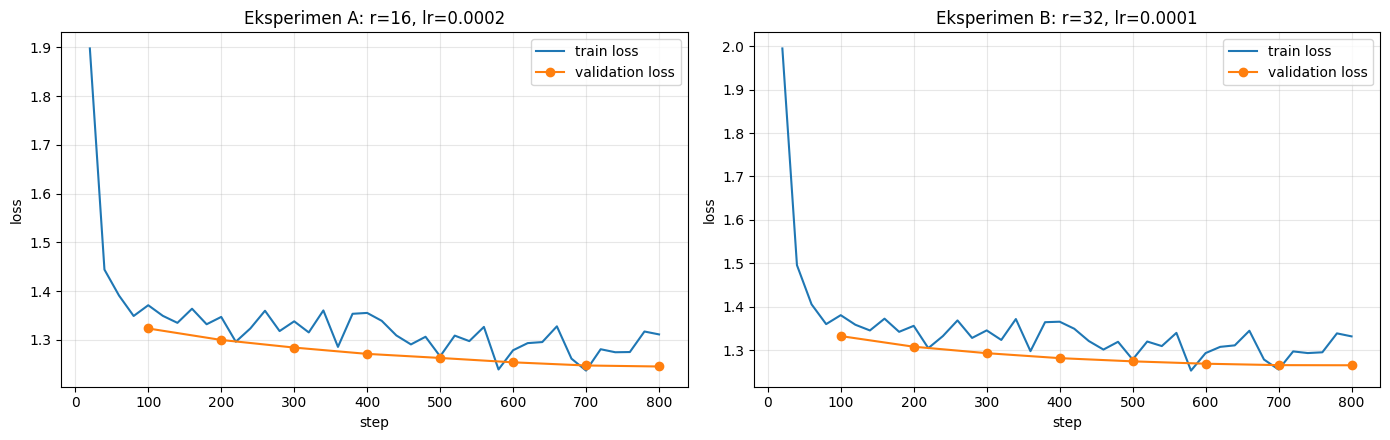

,r,lora_alpha,learning_rate,lr_scheduler_type,train_loss_akhir,val_loss_akhir,val_loss_min,gap_val_train
eksperimen,,,,,,,,
A,16,32,0.0002,linear,1.3114,1.2456,1.2456,-0.0658
B,32,32,0.0001,cosine,1.3316,1.2650,1.2650,-0.0666


In [10]:
import pandas as pd
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
summary = []
for ax, (name, hist) in zip(axes, histories.items()):
    df = pd.DataFrame(hist)
    tr = df.dropna(subset=["loss"]) if "loss" in df else pd.DataFrame()
    ev = df.dropna(subset=["eval_loss"])
    ax.plot(tr["step"], tr["loss"], label="train loss")
    ax.plot(ev["step"], ev["eval_loss"], marker="o", label="validation loss")
    ax.set_title(f"Eksperimen {name}: r={EXPERIMENTS[name]['r']}, lr={EXPERIMENTS[name]['learning_rate']}")
    ax.set_xlabel("step"); ax.set_ylabel("loss"); ax.legend(); ax.grid(alpha=0.3)
    summary.append({
        "eksperimen": name, **EXPERIMENTS[name],
        "train_loss_akhir": round(tr["loss"].iloc[-1], 4),
        "val_loss_akhir": round(ev["eval_loss"].iloc[-1], 4),
        "val_loss_min": round(ev["eval_loss"].min(), 4),
        "gap_val_train": round(ev["eval_loss"].iloc[-1] - tr["loss"].iloc[-1], 4),
    })
plt.tight_layout(); plt.show()
summary = pd.DataFrame(summary).set_index("eksperimen")
summary

Model terbaik dipilih berdasarkan **validation loss akhir terendah**. Selisih validation dengan train
loss (`gap_val_train`) dipakai untuk memastikan tidak ada *overfitting* (validation loss tidak naik
sementara train loss terus turun).

In [11]:
best = summary["val_loss_akhir"].idxmin()
print("Eksperimen terbaik:", best)
print(summary.loc[best])

Eksperimen terbaik: A
r                        16
lora_alpha               32
learning_rate        0.0002
lr_scheduler_type    linear
train_loss_akhir     1.3114
val_loss_akhir       1.2456
val_loss_min         1.2456
gap_val_train       -0.0658
Name: A, dtype: object


## 6. Uji inferensi singkat

In [12]:
del model; gc.collect(); torch.cuda.empty_cache()
model, tokenizer = FastLanguageModel.from_pretrained(
    model_name=f"adapters/exp_{best}", max_seq_length=MAX_SEQ_LEN, dtype=None, load_in_4bit=True)
tokenizer = get_chat_template(tokenizer, chat_template="chatml")
FastLanguageModel.for_inference(model)

def chat(question, max_new_tokens=256):
    messages = [{"role": "system", "content": SYSTEM_PROMPT}, {"role": "user", "content": question}]
    ids = tokenizer.apply_chat_template(messages, add_generation_prompt=True, return_tensors="pt").to("cuda")
    out = model.generate(input_ids=ids, max_new_tokens=max_new_tokens, temperature=0.3, do_sample=True)
    return tokenizer.decode(out[0][ids.shape[1]:], skip_special_tokens=True)

for q in ["Apa perbedaan antara undang-undang dan peraturan pemerintah?",
          "Berikan tiga tips agar tetap produktif saat bekerja dari rumah."]:
    print(f"### {q}\n{chat(q)}\n")

==((====))==  Unsloth 2026.11.1: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!
Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

[unsloth.chat_templates|WARNING]Unsloth: Will map <|im_end|> to EOS = <|im_end|>.


Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).


Unsloth: Restored added_tokens_decoder metadata in /kaggle/working/_unsloth_sentencepiece_temp/tokenizer_m99dy1sw/tokenizer_config.json.
Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


### Apa perbedaan antara undang-undang dan peraturan pemerintah?
Undang-undang dan peraturan pemerintah adalah dua istilah yang sering digunakan dalam konteks hukum, tetapi memiliki perbedaan yang signifikan. Undang-undang adalah peraturan yang ditetapkan oleh pemerintah dan disesuaikan dengan kebutuhan dan kepentingan masyarakat. Ini meliputi undang-undang dasar, undang-undang dasar negara, undang-undang lokal, undang-undang negara bagian, dan undang-undang negara. Undang-undang ini menetapkan prinsip dan aturan dasar yang membatasi kebebasan individu dan mengatur hubungan antara individu, pemerintah, dan organisasi.

Peraturan pemerintah, di sisi lain, adalah peraturan yang ditetapkan oleh pemerintah dan disesuaikan dengan kebutuhan dan kepentingan masyarakat. Ini meliputi peraturan yang meliputi hukum, kebijakan, dan regulasi yang mengatur hubungan antara pemerintah dan masyarakat. Peraturan

### Berikan tiga tips agar tetap produktif saat bekerja dari rumah.
1. Tetap terorganisir: 

## 7. Push model ke Hugging Face Hub (`merged_16bit`)

In [13]:
model.push_to_hub_merged(HF_REPO, tokenizer, save_method="merged_16bit", token=os.environ["HF_TOKEN"])
print(f"Model terunggah: https://huggingface.co/{HF_REPO}")

config.json:   0%|          | 0.00/775 [00:00<?, ?B/s]

Unsloth: Restored added_tokens_decoder metadata in tnromy/Qwen2.5-1.5B-Legal-ID-SFT/tokenizer_config.json.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub
Checking cache directory for required files...
Cache check failed: model.safetensors not found in local cache.
Not all required files found in cache. Will proceed with downloading.
Checking cache directory for required files...
Cache check failed: tokenizer.model not found in local cache.
Not all required files found in cache. Will proceed with downloading.


Unsloth: Preparing safetensor model files:   0%|          | 0/1 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 3.09GB            

model.safetensors: downloading bytes:           |  0.00B            

... (4 outputs left out)

New Data Upload: |          |  0.00B /  0.00B            

Validating:           |   0%            

Unsloth: Merging weights into 16bit: 100%|██████████| 1/1 [00:45<00:00, 45.42s/it]


Unsloth: Merge process complete. Saved to `/kaggle/working/tnromy/Qwen2.5-1.5B-Legal-ID-SFT`
Model terunggah: https://huggingface.co/tnromy/Qwen2.5-1.5B-Legal-ID-SFT


In [14]:
from huggingface_hub import HfApi
info = HfApi(token=os.environ["HF_TOKEN"]).model_info(HF_REPO)
print("Repo:", info.id, "| private:", info.private)
print([s.rfilename for s in info.siblings])

Repo: tnromy/Qwen2.5-1.5B-Legal-ID-SFT | private: False
['.gitattributes', 'README.md', 'chat_template.jinja', 'config.json', 'generation_config.json', 'model.safetensors', 'tokenizer.json', 'tokenizer_config.json']
